<a href="https://colab.research.google.com/github/habibiputrar/DeepLearning_B_2411531001_Habibi-Putra-Rizqullah/blob/main/Praktikum7/2411531001_Habibi_Putra_Rizqullah_Program7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum Deep Learning 7
## Autoencoder untuk Representasi dan Rekonstruksi Citra

**Nama:** Habibi Putra Rizqullah  
**NIM:** 2411531001  
**Kelas:** Deep Learning B

# BAGIAN I PRAKTIKUM

## 1. Implementasi Autoencoder

Autoencoder dengan dimensi laten 3 dilatih selama 10 epoch pada MNIST, lalu hasil rekonstruksinya ditampilkan.

100%|██████████| 9.91M/9.91M [00:00<00:00, 62.5MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.68MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 14.5MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 10.9MB/s]


Epoch [1/10], Loss: 0.0562
Epoch [2/10], Loss: 0.0536
Epoch [3/10], Loss: 0.0468
Epoch [4/10], Loss: 0.0384
Epoch [5/10], Loss: 0.0428
Epoch [6/10], Loss: 0.0372
Epoch [7/10], Loss: 0.0339
Epoch [8/10], Loss: 0.0341
Epoch [9/10], Loss: 0.0355
Epoch [10/10], Loss: 0.0343


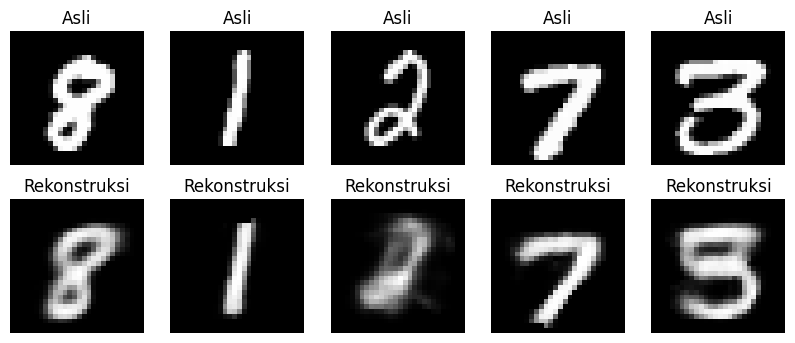

In [ ]:
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

# 1. Load dataset MNIST
transform = transforms.Compose([transforms.ToTensor()])
trainset = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=128, shuffle=True)

# 2. Definisikan model Autoencoder
class Autoencoder(nn.Module):
    def __init__(self):
        super(Autoencoder, self).__init__()
        # Encoder
        self.encoder = nn.Sequential(
            nn.Linear(28*28, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 12),
            nn.ReLU(),
            nn.Linear(12, 3)
        )
        # Decoder
        self.decoder = nn.Sequential(
            nn.Linear(3, 12),
            nn.ReLU(),
            nn.Linear(12, 64),
            nn.ReLU(),
            nn.Linear(64, 128),
            nn.ReLU(),
            nn.Linear(128, 28*28),
            nn.Sigmoid()
        )

    def forward(self, x):
        x = self.encoder(x)
        x = self.decoder(x)
        return x

model = Autoencoder()
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

# 3. Training loop
epochs = 10
for epoch in range(epochs):
    for data, _ in trainloader:
        img = data.view(data.size(0), -1)
        output = model(img)
        loss = criterion(output, img)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    print(f'Epoch [{epoch+1}/{epochs}], Loss: {loss.item():.4f}')

# 4. Visualisasi hasil rekonstruksi
with torch.no_grad():
    sample = next(iter(trainloader))[0][:5].view(-1, 28*28)
    reconstructed = model(sample)

    sample = sample.view(-1, 1, 28, 28)
    reconstructed = reconstructed.view(-1, 1, 28, 28)

    fig, axes = plt.subplots(2, 5, figsize=(10,4))
    for i in range(5):
        axes[0, i].imshow(sample[i].squeeze(), cmap='gray')
        axes[0, i].set_title("Asli")
        axes[0, i].axis('off')
        axes[1, i].imshow(reconstructed[i].squeeze(), cmap='gray')
        axes[1, i].set_title("Rekonstruksi")
        axes[1, i].axis('off')
    plt.show()

### Hasil Training dan Rekonstruksi

Loss yang tercetak adalah loss batch terakhir pada setiap epoch, sehingga nilainya naik turun, misalnya naik dari **0,0384** pada epoch 4 menjadi **0,0428** pada epoch 5. Secara umum loss turun dari **0,0562** pada epoch 1 menjadi **0,0343** pada epoch 10.

Pada gambar, digit 8, 1, dan 7 masih dapat dikenali. Digit 2 menjadi buram dan sulit dikenali, sedangkan digit 3 direkonstruksi menjadi mirip 5. Hasilnya buram karena 784 piksel hanya disimpan dalam 3 angka.

# BAGIAN II TUGAS INDIVIDU

Tiga model dilatih selama 10 epoch: AE_1 (laten 3, tanpa noise), AE_2 (laten 3, noise Gaussian 0,1), dan AE_3 (laten 2, tanpa noise). Hasilnya dibandingkan melalui loss, citra rekonstruksi, dan tabel.

## 1. Persiapan Library

Library yang digunakan adalah PyTorch, torchvision, pandas, dan matplotlib. Seed diatur ke 42 agar hasilnya bisa diulang.

In [ ]:
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

torch.manual_seed(42)
random.seed(42)
np.random.seed(42)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

cpu


## 2. Memuat Dataset

MNIST dimuat dengan `ToTensor()` sehingga nilai piksel berada di rentang 0 sampai 1. Batch size data latih adalah 128 dan data uji 256.

In [ ]:
transform = transforms.Compose([transforms.ToTensor()])

trainset = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=transform)
testset = torchvision.datasets.MNIST(root='./data', train=False, download=True, transform=transform)

trainloader = torch.utils.data.DataLoader(trainset, batch_size=128, shuffle=True)
testloader = torch.utils.data.DataLoader(testset, batch_size=256, shuffle=False)

print(len(trainset), len(testset))

60000 10000


### Hasil Dataset

Data latih berjumlah **60.000** citra dan data uji **10.000** citra.

## 3. Model Autoencoder

Arsitekturnya sama seperti pada Bagian I: 784, 128, 64, 12, lalu dimensi laten. `latent_dim` dibuat sebagai parameter agar kelas yang sama bisa dipakai untuk laten 3 dan laten 2. Fungsi `add_noise` menambahkan noise Gaussian lalu membatasi nilai piksel di rentang 0 sampai 1.

In [ ]:
class Autoencoder(nn.Module):
    def __init__(self, latent_dim=3):
        super(Autoencoder, self).__init__()
        self.encoder = nn.Sequential(
            nn.Linear(28*28, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 12),
            nn.ReLU(),
            nn.Linear(12, latent_dim)
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 12),
            nn.ReLU(),
            nn.Linear(12, 64),
            nn.ReLU(),
            nn.Linear(64, 128),
            nn.ReLU(),
            nn.Linear(128, 28*28),
            nn.Sigmoid()
        )

    def forward(self, x):
        x = self.encoder(x)
        x = self.decoder(x)
        return x


def add_noise(img, std):
    if std == 0:
        return img
    return torch.clamp(img + torch.randn_like(img) * std, 0, 1)

## 4. Fungsi Training

Untuk model dengan noise, inputnya adalah citra yang sudah ditambah noise, tetapi loss tetap dihitung terhadap citra aslinya. Loss yang dicetak adalah rata-rata seluruh batch pada setiap epoch.

In [ ]:
def train_model(latent_dim, noise_std, epochs=10):
    torch.manual_seed(42)
    model = Autoencoder(latent_dim).to(device)
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    history = []

    for epoch in range(epochs):
        total, n = 0.0, 0
        for data, _ in trainloader:
            img = data.view(data.size(0), -1).to(device)
            output = model(add_noise(img, noise_std))
            loss = criterion(output, img)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total += loss.item()
            n += 1
        history.append(total / n)
        print(f'Epoch [{epoch+1}/{epochs}], Loss: {history[-1]:.4f}')
    return model, history

## 5. Training AE_1

AE_1 memakai dimensi laten 3 tanpa noise.

In [ ]:
ae1, hist1 = train_model(latent_dim=3, noise_std=0)

Epoch [1/10], Loss: 0.0686
Epoch [2/10], Loss: 0.0507
Epoch [3/10], Loss: 0.0442
Epoch [4/10], Loss: 0.0416
Epoch [5/10], Loss: 0.0399
Epoch [6/10], Loss: 0.0387
Epoch [7/10], Loss: 0.0379
Epoch [8/10], Loss: 0.0374
Epoch [9/10], Loss: 0.0369
Epoch [10/10], Loss: 0.0364


### Hasil Training AE_1

Loss turun dari **0,0686** pada epoch 1 menjadi **0,0364** pada epoch 10. Penurunan terbesar terjadi dari epoch 1 ke epoch 2.

## 6. Training AE_2

AE_2 memakai dimensi laten 3, dengan noise Gaussian 0,1 pada inputnya.

In [ ]:
ae2, hist2 = train_model(latent_dim=3, noise_std=0.1)

Epoch [1/10], Loss: 0.0691
Epoch [2/10], Loss: 0.0496
Epoch [3/10], Loss: 0.0440
Epoch [4/10], Loss: 0.0412
Epoch [5/10], Loss: 0.0394
Epoch [6/10], Loss: 0.0382
Epoch [7/10], Loss: 0.0373
Epoch [8/10], Loss: 0.0366
Epoch [9/10], Loss: 0.0360
Epoch [10/10], Loss: 0.0355


### Hasil Training AE_2

Loss turun dari **0,0691** menjadi **0,0355**, hampir sama dengan AE_1 walaupun inputnya diberi noise.

## 7. Training AE_3

AE_3 memakai dimensi laten 2 tanpa noise.

In [ ]:
ae3, hist3 = train_model(latent_dim=2, noise_std=0)

Epoch [1/10], Loss: 0.0671
Epoch [2/10], Loss: 0.0523
Epoch [3/10], Loss: 0.0494
Epoch [4/10], Loss: 0.0469
Epoch [5/10], Loss: 0.0451
Epoch [6/10], Loss: 0.0440
Epoch [7/10], Loss: 0.0431
Epoch [8/10], Loss: 0.0425
Epoch [9/10], Loss: 0.0420
Epoch [10/10], Loss: 0.0415


### Hasil Training AE_3

Loss turun dari **0,0671** menjadi **0,0415**. Nilai akhir ini paling tinggi dari ketiga model.

## 8. Kurva Loss

Loss ketiga model pada setiap epoch digambar dalam satu grafik.

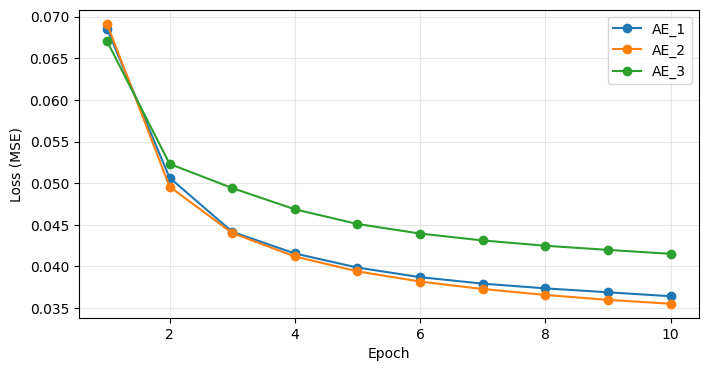

In [ ]:
epochs = range(1, 11)
plt.figure(figsize=(8, 4))
plt.plot(epochs, hist1, marker='o', label='AE_1')
plt.plot(epochs, hist2, marker='o', label='AE_2')
plt.plot(epochs, hist3, marker='o', label='AE_3')
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Hasil Kurva Loss

Kurva AE_1 dan AE_2 berdekatan, dengan AE_2 sedikit di bawah AE_1 sejak epoch 2. Kurva AE_3 berada di atas keduanya sejak epoch 2. Ketiganya mulai datar pada epoch 8 sampai 10, tetapi masih turun sedikit.

## 9. Rekonstruksi Citra

Delapan citra data uji direkonstruksi oleh ketiga model. Baris pertama adalah citra asli.

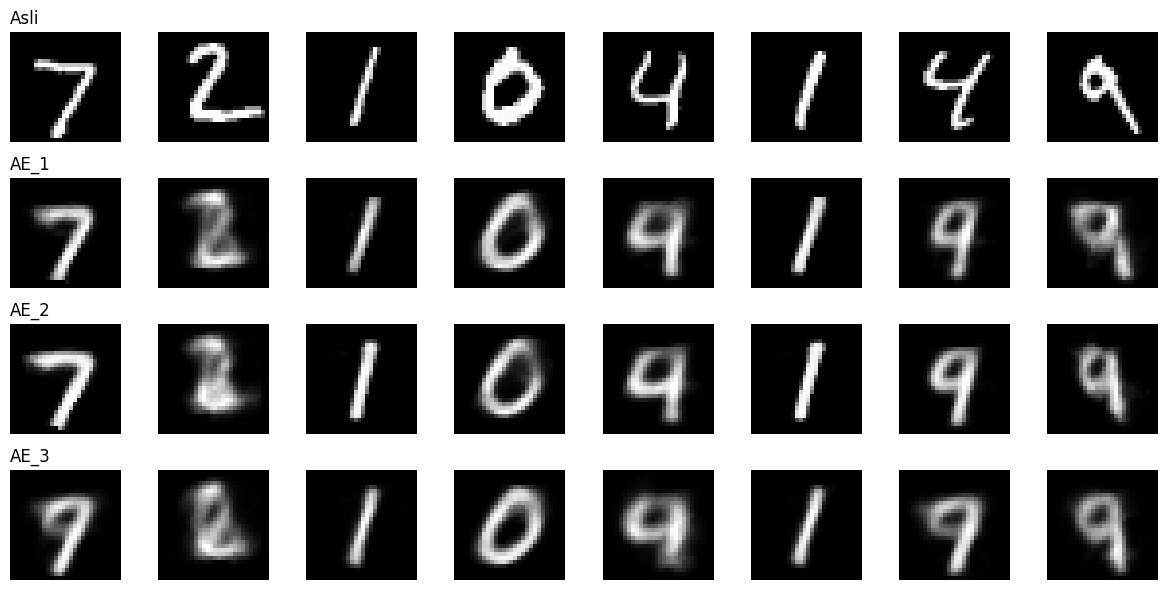

In [ ]:
def reconstruct(model, x):
    model.eval()
    with torch.no_grad():
        return model(x.to(device)).cpu()

images, labels = next(iter(testloader))
sample = images[:8].view(-1, 28*28)

rows = [('Asli', sample),
        ('AE_1', reconstruct(ae1, sample)),
        ('AE_2', reconstruct(ae2, sample)),
        ('AE_3', reconstruct(ae3, sample))]

fig, axes = plt.subplots(4, 8, figsize=(12, 6))
for r, (name, imgs) in enumerate(rows):
    for c in range(8):
        axes[r, c].imshow(imgs[c].view(28, 28), cmap='gray')
        axes[r, c].axis('off')
    axes[r, 0].set_title(name, loc='left')
plt.tight_layout()
plt.show()

### Hasil Rekonstruksi

Pada AE_1 dan AE_2, digit 7, 1, dan 0 sudah mirip aslinya. Digit 2 buram, dan kedua digit 4 hasilnya mirip 9.

Pada AE_3 hasilnya lebih buram. Digit 7 menjadi mirip 9, dan garis tipis pada digit 4 dan 9 hilang.

## 10. Representasi Laten AE_3

Karena dimensinya dua, representasi laten AE_3 bisa digambar langsung. Plot memakai 5.000 citra uji dan warna menunjukkan label digit.

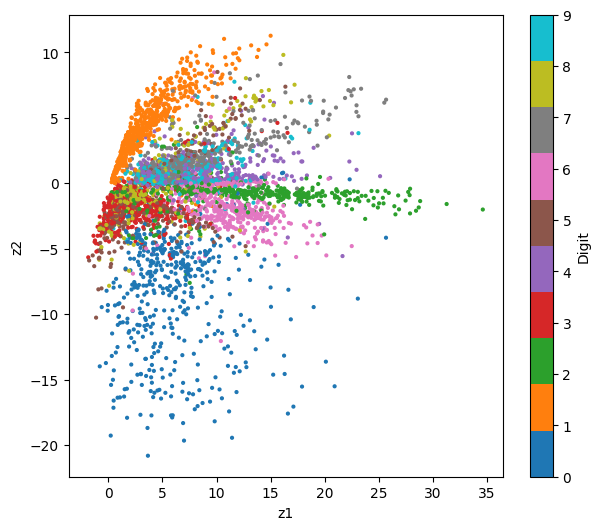

In [ ]:
ae3.eval()
zs, ys = [], []
with torch.no_grad():
    for data, y in testloader:
        zs.append(ae3.encoder(data.view(data.size(0), -1).to(device)).cpu())
        ys.append(y)
z = torch.cat(zs)[:5000]
y = torch.cat(ys)[:5000]

plt.figure(figsize=(7, 6))
plt.scatter(z[:, 0], z[:, 1], c=y, cmap='tab10', s=4)
plt.colorbar(label='Digit')
plt.xlabel('z1')
plt.ylabel('z2')
plt.show()

### Hasil Representasi Laten

Digit 0 (biru) dan digit 1 (oranye) berada di daerah yang terpisah, dan digit 2 (hijau) memanjang ke arah kanan. Digit 4, 7, dan 9 bercampur di tengah. Ini sesuai dengan kesalahan rekonstruksi AE_3 pada digit tersebut.

## 11. Denoising

Citra uji diberi noise Gaussian 0,1, lalu dimasukkan ke AE_1 (dilatih tanpa noise) dan AE_2 (dilatih dengan noise).

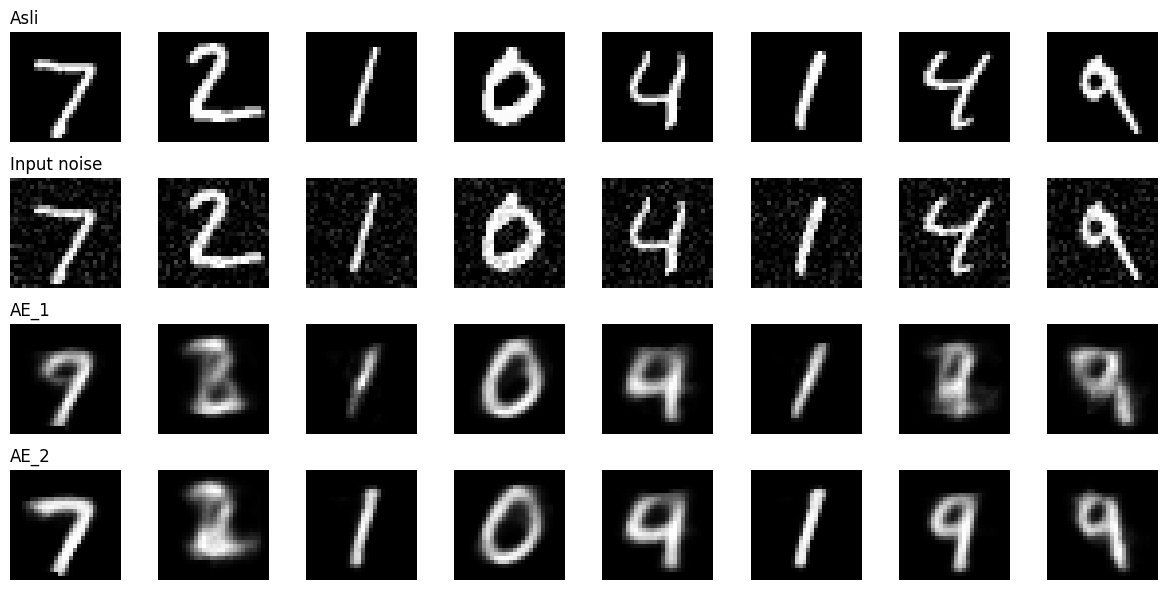

In [ ]:
torch.manual_seed(42)
noisy = add_noise(sample, 0.1)

rows = [('Asli', sample),
        ('Input noise', noisy),
        ('AE_1', reconstruct(ae1, noisy)),
        ('AE_2', reconstruct(ae2, noisy))]

fig, axes = plt.subplots(4, 8, figsize=(12, 6))
for r, (name, imgs) in enumerate(rows):
    for c in range(8):
        axes[r, c].imshow(imgs[c].view(28, 28), cmap='gray')
        axes[r, c].axis('off')
    axes[r, 0].set_title(name, loc='left')
plt.tight_layout()
plt.show()

### Hasil Denoising

Hasil AE_1 agak rusak: angka 1 di kolom ketiga hampir putus, angka 7 yang pertama menjadi mirip 9, dan digit 4 yang kedua menjadi tidak jelas. Pada AE_2, angka 1 tetap utuh dan angka 7 tetap terbaca sebagai 7. Digit 2 masih buram dan digit 4 masih mirip 9 pada AE_2, jadi noise bukan satu-satunya penyebab kesalahan.

## 12. MSE pada Input Bernoise

MSE dihitung pada seluruh data uji yang diberi noise 0,1, dengan citra asli sebagai target.

In [ ]:
def test_mse(model, noise_std):
    model.eval()
    torch.manual_seed(42)
    total, count = 0.0, 0
    with torch.no_grad():
        for data, _ in testloader:
            img = data.view(data.size(0), -1).to(device)
            out = model(add_noise(img, noise_std))
            total += ((out - img) ** 2).sum().item()
            count += img.numel()
    return total / count

print('AE_1 pada input noise 0.1:', round(test_mse(ae1, 0.1), 4))
print('AE_2 pada input noise 0.1:', round(test_mse(ae2, 0.1), 4))

AE_1 pada input noise 0.1: 0.0388
AE_2 pada input noise 0.1: 0.0354


### Hasil MSE

MSE AE_1 adalah **0,0388** dan AE_2 adalah **0,0354**. Nilai AE_2 lebih kecil, tetapi selisihnya tidak besar karena noise 0,1 masih ringan.

## 13. Tabel Hasil Eksperimen

Hasil ketiga eksperimen ditampilkan dalam tabel berikut.

In [ ]:
kualitas = {"AE_1": "Cukup baik", "AE_2": "Cukup baik", "AE_3": "Buram, detail hilang"}

hasil = pd.DataFrame({
    'Eksperimen': ['AE_1', 'AE_2', 'AE_3'],
    'Dimensi Laten': [3, 3, 2],
    'Noise': ['Tidak ada', 'Gaussian(0.1)', 'Tidak ada'],
    'Loss Akhir': [round(hist1[-1], 4), round(hist2[-1], 4), round(hist3[-1], 4)],
    'Kualitas Rekonstruksi': [kualitas['AE_1'], kualitas['AE_2'], kualitas['AE_3']]
})
hasil

,Eksperimen,Dimensi Laten,Noise,Loss Akhir,Kualitas Rekonstruksi
0,AE_1,3,Tidak ada,0.0364,Cukup baik
1,AE_2,3,Gaussian(0.1),0.0355,Cukup baik
2,AE_3,2,Tidak ada,0.0415,"Buram, detail hilang"


### Hasil Tabel

Loss akhir AE_1 dan AE_2 hampir sama (**0,0364** dan **0,0355**) dengan kualitas cukup baik. Loss akhir AE_3 paling tinggi (**0,0415**) dan hasilnya buram. Kolom kualitas diisi dari perbandingan gambar rekonstruksi.

## 14. Ringkasan Hasil

Dimensi laten yang lebih kecil membuat rekonstruksi lebih buruk. Loss naik dari **0,0364** (laten 3) menjadi **0,0415** (laten 2), dan banyak detail digit yang hilang.

Noise 0,1 hampir tidak mengubah loss training (**0,0364** dan **0,0355**). Perbedaannya terlihat pada input bernoise: MSE AE_2 sebesar **0,0354** lebih kecil dari AE_1 sebesar **0,0388**, karena AE_2 dilatih untuk mengembalikan citra bersih dari input yang terganggu.

Kesalahan seperti digit 4 yang menjadi mirip 9 muncul pada ketiga model, jadi dimensi laten 3 pun belum cukup untuk membedakan semua digit. Hasil ini berlaku untuk konfigurasi yang diuji, yaitu MLP sederhana dengan 10 epoch.